<a href="https://colab.research.google.com/github/a15cardoso/neurodata_firstSemester_pythonWS/blob/main/Advanced_Python_WS_Lesson_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Prompt Used in Gemini
Act as a computational neuroscientist and Python expert. Help me solve a neurodata homework assignment simulating the passive voltage decay of a single neuron's membrane.
Here are the exact parameters:

 * Equation: v(t)=A⋅e^(-γt)
 * Initial peak voltage (A): 60" mV"
 * Sampling frequency: 20" kHz"
 * Simulation duration: 250" ms"
 * Membrane half-life (t_(1/2)): 12" ms"
 * Decay constant formula: γ=ln⁡(2)/t_(1/2)

Please write clean, well-commented Python code using numpy and matplotlib that calculates this time series, generates a professional plot with a title, legend, and a clear visual marker for the half-life point.

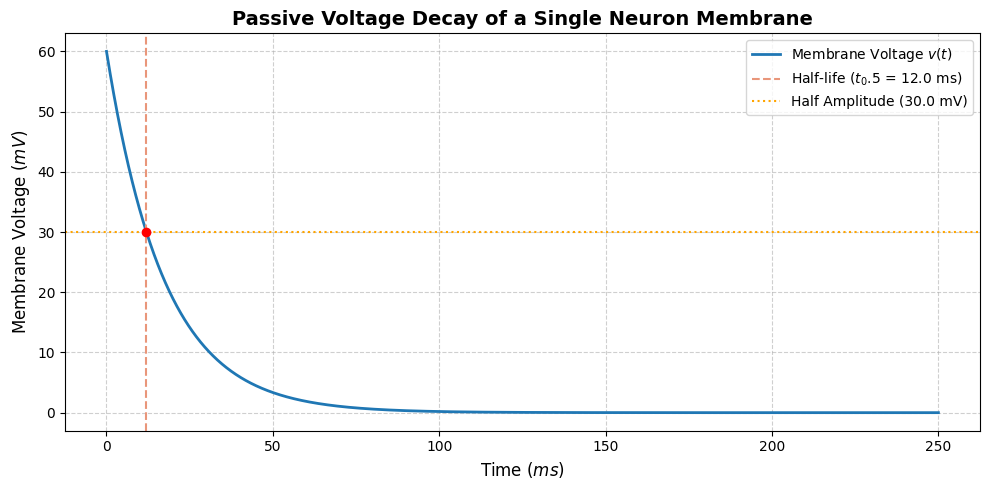

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETER DEFINITION
# ==========================================
A = 60.0             # Initial peak voltage in millivolts (mV)
t_half = 12.0        # Membrane half-life in milliseconds (ms)
fs = 20000.0         # Sampling frequency in Hz (20,000 samples per second)
duration = 250.0     # Total simulation duration in milliseconds (ms)

# ==========================================
# 2. TIME & DECAY CONSTANT COMPUTATION
# ==========================================
# Convert sampling frequency from Hz to ms^-1 to find the time step (dt)
# dt = 1 second / fs = 1000 ms / 20000 Hz = 0.05 ms
dt = 1000.0 / fs

# Create the time array from 0 to 250 ms with steps of dt
t = np.arange(0, duration + dt, dt)

# Calculate the decay constant (gamma) using the provided hint
gamma = np.log(2) / t_half

# ==========================================
# 3. VOLTAGE DECAY SIMULATION
# ==========================================
# Compute exponential voltage decay: v(t) = A * e^(-gamma * t)
v = A * np.exp(-gamma * t)

# ==========================================
# 4. PLOTTING THE RESULTS
# ==========================================
plt.figure(figsize=(10, 5))

# Plot membrane voltage curve
plt.plot(t, v, label='Membrane Voltage $v(t)$', color='#1f77b4', linewidth=2)

# Mark the half-life on the plot
half_voltage = A / 2.0
plt.axvline(x=t_half, color='darksalmon', linestyle='--', label=f'Half-life ($t_{1/2}$ = {t_half} ms)')
plt.axhline(y=half_voltage, color='orange', linestyle=':', label=f'Half Amplitude ({half_voltage} mV)')
plt.scatter([t_half], [half_voltage], color='red', zorder=5)

# Figure formatting: Title, labels, legend, and grid
plt.title('Passive Voltage Decay of a Single Neuron Membrane', fontsize=14, fontweight='bold')
plt.xlabel('Time ($ms$)', fontsize=12)
plt.ylabel('Membrane Voltage ($mV$)', fontsize=12)
plt.legend(loc='upper right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## How I evaluated the code and the graphic

Code: I evaluated whether the code was:

* Well-commented: Each part and variable was clearly stated and thoroughly commented to make the code easy to follow.

* Accurate: I checked each variable to ensure it matched the values given in the exercise.

* Complete: I plotted the results to guarantee that the entire task was successfully performed and completed.

Figure: To determine if the figure made sense based on the task assigned to Gemini, I analyzed whether it satisfied all requirements, such as:

* Title: "Passive voltage decay of a single neuron membrane" — This title clearly states the biological process being modeled.

* Legend: It clarifies all the main properties we are interested in: the membrane voltage function, the half-time, and the half-amplitude.

* Sampling resolution: To acquire a smooth, continuous exponential curve without visible digitization artifacts, the figure uses a 0.05ms resolution, totaling $5000$ points to represent the curve.

* Half-life marker: As heavily emphasized by the professor in class, I clearly identified it in the graphic to precisely pinpoint the intersection at the half-amplitude point at t = 12ms and a membrane voltage of 30mV.

Evaluation of the results:

* Physiological Interpretation: The simulation models a neuronal membrane, equivalent to an integrate-and-fire or leaky bucket model without active spike generation. Following the stimulus, charge leaks out across the lipid bilayer through ion channels.

* Time constant correlation: As highlighted in class, I choose to pinpoint the half-life point. Why does it matters? The half-life is directly linked to the membrane time constant. This relationship is crucial because half-life measures a 50% reduction in the neuron's membrane voltage.

* Sampling Rate Adequacy: Also mentioned in class, a 20kHz sampling rate provides more than adequate temporal resolution for a 12ms half-life decay process, preventing aliasing and accurately capturing rapid voltage transients.